# KROME-X quick start

Generate a chemistry project from a network and a few physics options,
compile it, and solve one cell: the README's quick start, with its
results. A C++17 compiler is needed for the build.

In [1]:
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 90

In [2]:
# KROME-X: installed with pip, or this checkout (three folders up)
import sys, pathlib
try:
    import kromex
except ImportError:
    sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[2]))
    import kromex

## The configuration

A `Preprocessor` holds the network and the options, grouped in sections
(`thermal`, `solver`, `radiation`, ...). Every value is checked when it
is set.

In [3]:
from kromex import Preprocessor, ConfigError

kp = Preprocessor(network="primordial")     # a shipped network, or a .knet path
kp.thermal.cooling = ["ATOMIC", "H2"]
kp.thermal.heating = ["CHEM", "COMPRESS"]
kp.project.bindings = ["python"]
kp

Preprocessor()
  project.network = 'primordial'
  project.bindings = ['python']
  thermal.cooling = ['ATOMIC', 'H2']
  thermal.heating = ['CHEM', 'COMPRESS']

A misspelled option is an error that names the closest ones:

In [4]:
try:
    kp.thermal.colling = ["H2"]
except ConfigError as e:
    print(e)

unknown option 'thermal.colling' (the thermal options: cooling, heating, floor, gamma, h2_opacity, metals, coolant_files, escape, levels, photo_pumping, cmb_pumping, photoelectric, wd01); did you mean thermal.cooling or thermal.heating or thermal.cmb_pumping?


## Generate, build, solve

`run()` writes the project, `build()` compiles it and returns its Python
`Network`. The solving is yours: here one cell of primordial gas at
n_H = 10^4 cm^-3 and 100 K, for 1000 yr, with Tgas evolved.

In [5]:
kp.run("build_quickstart")       # the project folder
net = kp.build()
print(net.nspec, "species,", net.nrea, "reactions; parameters:", net.params)
print("required:", net.required)

wrote build_quickstart/net_primordial.hpp  (12 species, 38 reactions; split into 8 files; 19 runtime files copied, wrote Makefile + example.cpp + example.py)


12 species, 38 reactions; parameters: ('gamma_ad', 'Tcmb', 'tff')
required: {'tff': "thermal.heating = ['COMPRESS']"}


In [6]:
n = net.densities({"H": 1e4, "H+": 1.0, "e-": 1.0, "He": 775.0})   # [cm^-3]
opts = net.options(evolve_T=True)          # Tgas evolved with the chemistry
r = net.solve(n, 100.0, 3.15e10, par={"tff": 1e14}, opts=opts)     # 1000 yr
print("Tgas = %.1f K, n(H2) = %.3g cm^-3, flag %d" % (r.Tgas, r.n[net.idx("H2")], r.flags))

Tgas = 100.0 K, n(H2) = 0.0292 cm^-3, flag 0


`tff` (the compression time of the COMPRESS heating) has no default:
`net.required` lists such parameters, and a solve without them is
rejected.

## Following the cell in time

The same cell over 10^6 yr, in steps growing by 10%: H2 forms (through
H-), while the compression (tff = 10^14 s, about 3 Myr) slowly heats the
gas, faster than the still scarce H2 can cool it.

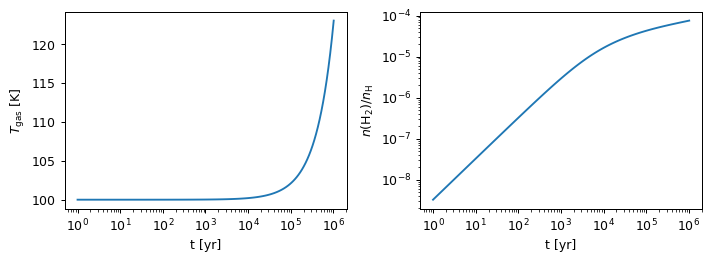

In [7]:
import numpy as np
import matplotlib.pyplot as plt

t, dt, T, x = 0.0, 3.15e7, 100.0, n.copy()
hist = []
while t < 3.15e13:                        # 1e6 yr
    r = net.solve(x, T, dt, par={"tff": 1e14}, opts=opts)
    x, T, t, dt = r.n, float(r.Tgas), t + dt, dt * 1.1
    hist.append((t / 3.15e7, T, x[net.idx("H2")] / 1e4))
t_yr, Tg, xH2 = np.array(hist).T
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3))
a.semilogx(t_yr, Tg); a.set(xlabel="t [yr]", ylabel="$T_\\mathrm{gas}$ [K]")
b.loglog(t_yr, xH2); b.set(xlabel="t [yr]", ylabel="$n(\\mathrm{H_2}) / n_\\mathrm{H}$")
fig.tight_layout()

## The configuration as a file

The options can live in a TOML file, the same one `python3 -m kromex
FILE` reads, and every generated project records its own
(`krome.toml`).

In [8]:
kp.save("build_quickstart.toml")
print(open("build_quickstart.toml").read())
assert Preprocessor.from_file("build_quickstart.toml").to_dict() == kp.to_dict()

# the network, the project directory and what is generated
[project]
network = "primordial"
# outdir: default
bindings = ["python"]
single = false
runtime = true

# how the rate coefficients and the rate equations are written
[rates]
outside = "asym"
rhs = "auto"
reactant_multiplicity = false
screening = false
check_reverse = false

# the thermal processes, fixed in the generated code
[thermal]
cooling = ["ATOMIC", "H2"]
heating = ["CHEM", "COMPRESS"]
floor = false
gamma = "CONST"
h2_opacity = ""
metals = []
coolant_files = []
escape = ""
# levels: default
photo_pumping = false
cmb_pumping = false
photoelectric = "BT94"
wd01 = []

# photon bins, shielding and column densities
[radiation]
evolve = false
shielding = "WG11"
num2col = "default"
habing_dust_shielding = false
secondary_ionization = []

# dust tables and the dust state
[dust]
tables = ""
evolve_Td = false
evolve = []
gas_total = false

# grain-surface chemistry
[surface]
binding_energies = "KROME"
nu = "HASEGAWA"
competition 